# Оптимизация гиперпараметров дерева решений
### Лабораторная работа №3 · Titanic

В работе я исследую, как настройки дерева решений влияют на предсказание выживания пассажиров Titanic. Сравниваю полный перебор сетки и случайный поиск, оцениваю качество и разброс результатов на кросс-валидации, затем проверяю выбранную модель на отложенной выборке.

| Задача | Модель | Основная метрика | Разбиение |
|:---|:---|:---|:---|
| Бинарная классификация `Survived` | Дерево решений | F1 класса «выжил» | 80% train / 20% test |

**Исходная модель.** В качестве baseline я использую дерево из предыдущей работы: `max_depth=7`, `min_samples_leaf=5`, `random_state=42`. Остальные настройки оставляю стандартными. Перед оптимизацией повторно измеряю его качество на тех же пяти folds.

**Почему F1.** Мне важно учитывать как ложные прогнозы выживания, так и пропуски выживших. F1 объединяет precision и recall, тогда как accuracy может скрывать ошибки на менее частом классе.

**Организация эксперимента.** Обработку пропусков и кодирование категорий я включаю в Pipeline. На каждом fold преобразования обучаются только на его обучающей части. Для выбора параметров использую CV, а test оцениваю после завершения поиска.

**Ограничения данных.** Я сохраняю разбиение из предыдущей работы, поэтому test уже не является новым слепым контролем. Кроме того, пассажиры одного билета могут оказаться в разных частях выборки. Полученные оценки относятся к случайному разбиению пассажиров и не гарантируют такого же качества на новых семьях.


In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import platform
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV, ParameterGrid,
                                     validation_curve)
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
DATA_DIR = Path('.') if Path('titanic.csv').exists() else Path('hyperparameters')
ARTIFACTS = DATA_DIR / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.titlesize': 13,
                     'axes.titleweight': 'bold', 'axes.spines.top': False,
                     'axes.spines.right': False, 'grid.alpha': 0.25,
                     'figure.facecolor': '#f8fafc', 'axes.facecolor': '#ffffff',
                     'axes.prop_cycle': plt.cycler(color=['#2563eb', '#f59e0b', '#14b8a6'])})
COLORS = ['#64748b', '#2563eb', '#14b8a6']
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'sklearn': sklearn.__version__}
print(versions)
raw = (DATA_DIR / 'titanic.csv').read_bytes()
assert hashlib.sha256(raw).hexdigest() == '7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f'
df = pd.read_csv(DATA_DIR / 'titanic.csv')
assert df.shape == (891, 12)
NUM = ['Age', 'SibSp', 'Parch', 'Fare']
CAT = ['Pclass', 'Sex', 'Embarked']
FEATURES = NUM + CAT
train_idx, test_idx = train_test_split(df.index, test_size=0.2,
                                      stratify=df.Survived, random_state=SEED)
X_train, y_train = df.loc[train_idx, FEATURES], df.loc[train_idx, 'Survived']
assert set(train_idx).isdisjoint(test_idx)
assert 'Survived' not in FEATURES
pd.DataFrame({'PassengerId': df.PassengerId,
              'split': np.where(df.index.isin(train_idx), 'train', 'test')}).to_csv(
    ARTIFACTS / 'split.csv', index=False)
print('Train:', len(train_idx), 'Test (отложен):', len(test_idx))
display(y_train.value_counts().rename('train_count'))

prepare = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUM),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT)
])
baseline = Pipeline([('prepare', prepare),
                     ('model', DecisionTreeClassifier(max_depth=7, min_samples_leaf=5,
                                                       random_state=SEED))])

cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
for tr, va in cv:
    assert set(tr).isdisjoint(va)
display(baseline.named_steps['model'].get_params())

{'python': '3.14.4', 'numpy': '2.5.4', 'pandas': '3.1.0', 'sklearn': '1.9.1'}
Train: 712 Test (отложен): 179


Survived
0    439
1    273
Name: train_count, dtype: int64

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 7,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 5,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

## 1. Исходное качество и кросс-валидация

Я использую **StratifiedKFold с пятью folds**, перемешиванием и `random_state=42`. На каждом шаге примерно 570 пассажиров участвуют в обучении и 142 — в проверке. Стратификация сохраняет соотношение классов. Пять folds дают приемлемый размер обучающей части при умеренном времени расчёта.

Кросс-валидация позволяет проверить модель на нескольких частях данных и уменьшает зависимость результата от одного удачного разбиения. Единственного разбиения недостаточно для устойчивого подбора: состав валидационной выборки может заметно менять оценку.

Если многократно выбирать параметры по test, модель постепенно подстраивается к особенностям этой выборки, и оценка становится завышенной. Поэтому я не использую test в поиске. При этом и лучший результат CV после перебора может оказаться оптимистичным: он выбран среди многих кандидатов. Обучающие части folds пересекаются, поэтому их оценки нельзя считать полностью независимыми.


In [2]:
start = perf_counter()
base_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring='f1',
                         return_train_score=True, n_jobs=1, error_score='raise')
base_seconds = perf_counter() - start
display(pd.DataFrame({'fold': np.arange(1, 6), 'train_F1': base_cv['train_score'],
                      'validation_F1': base_cv['test_score']}))
print(f"Baseline CV F1: {base_cv['test_score'].mean():.4f} ± {base_cv['test_score'].std():.4f}")

,fold,train_F1,validation_F1
0,1,0.825871,0.747664
1,2,0.818859,0.693069
2,3,0.807018,0.767677
3,4,0.833747,0.716981
4,5,0.835322,0.740000


Baseline CV F1: 0.7331 ± 0.0258


## 2. Пространство гиперпараметров

| Параметр | Смысл и гипотеза | Grid Search | Random Search |
|---|---|---|---|
| `max_depth` | Максимальная глубина. Малая глубина может недообучать, большая — запоминать шум. | 2, 4, 7, None | 2, 3, 4, 5, 6, 7, 9, 12, 16, None |
| `min_samples_leaf` | Минимум объектов в листе. Увеличение сглаживает прогноз и снижает сложность, слишком большое ведёт к недообучению. | 1, 3, 5, 12 | 1, 2, 3, 4, 5, 7, 9, 12, 16, 24 |
| `max_features` | Число признаков, рассматриваемых при разбиении. Ограничение добавляет случайность и может ослабить переобучение, но для одного дерева повышает риск пропустить полезный признак. | None, sqrt, 0.7 | None, sqrt, 0.5, 0.7, 0.9 |

`None` для глубины снимает ограничение; для max_features разрешает все признаки.
Доли max_features применяются к признакам после one-hot кодирования. Масштабирование дереву не требуется.
Остальные параметры я фиксирую, включая `min_samples_split=2`, `criterion='gini'`, `splitter='best'`.

Grid проверяет **48 комбинаций**, Random выбирает **48 различных комбинаций из 500** без возвращения
(все распределения заданы конечными списками). Обе стратегии выполняют по 240 обучений на CV и одному refit.
Бюджет равен по числу кандидатов и folds; время может различаться из-за сложности деревьев.
Случайный поиск покрывает больше различных значений, что полезно при широком пространстве и
неодинаковой важности параметров. Он не гарантирует превосходство сетки.

Финальную стратегию я выбираю по максимальному среднему CV F1 среди победителей двух поисков. При точном равенстве предпочитаю Grid. Кривые использую для анализа поведения модели, без расширения пространства поиска.

In [3]:
grid_space = {'model__max_depth': [2, 4, 7, None],
              'model__min_samples_leaf': [1, 3, 5, 12],
              'model__max_features': [None, 'sqrt', 0.7]}
random_space = {'model__max_depth': [2, 3, 4, 5, 6, 7, 9, 12, 16, None],
                'model__min_samples_leaf': [1, 2, 3, 4, 5, 7, 9, 12, 16, 24],
                'model__max_features': [None, 'sqrt', 0.5, 0.7, 0.9]}
BUDGET = len(ParameterGrid(grid_space))
assert BUDGET == 48
searches = {
    'Grid Search': GridSearchCV(clone(baseline), grid_space, cv=cv, scoring='f1',
                               n_jobs=1, return_train_score=True, error_score='raise'),
    'Random Search': RandomizedSearchCV(clone(baseline), random_space, n_iter=BUDGET,
                                       random_state=SEED, cv=cv, scoring='f1', n_jobs=1,
                                       return_train_score=True, error_score='raise')
}
times = {}
for name, search in searches.items():
    start = perf_counter()
    search.fit(X_train, y_train)
    times[name] = perf_counter() - start
    pd.DataFrame(search.cv_results_).to_csv(
        ARTIFACTS / ('grid_cv.csv' if name == 'Grid Search' else 'random_cv.csv'), index=False)
    print(name, search.best_params_, f'CV F1={search.best_score_:.4f}')
    assert len(search.cv_results_['params']) == BUDGET
search_summary = pd.DataFrame([
    {'method': name, 'candidates': len(search.cv_results_['params']),
     'CV_fits': BUDGET * len(cv), 'CV_F1': search.best_score_,
     'CV_std': search.cv_results_['std_test_score'][search.best_index_],
     'seconds_including_refit': times[name], 'parameters': str(search.best_params_)}
    for name, search in searches.items()
]).set_index('method')
display(search_summary)
search_summary.to_csv(ARTIFACTS / 'search_summary.csv')
selected_name = max(searches, key=lambda name: searches[name].best_score_)
selected_params = searches[selected_name].best_params_.copy()
print('До открытия test выбрана стратегия:', selected_name)
print('Фиксируем параметры:', selected_params)

Grid Search {'model__max_depth': 7, 'model__max_features': 0.7, 'model__min_samples_leaf': 3} CV F1=0.7430


Random Search {'model__min_samples_leaf': 5, 'model__max_features': 0.9, 'model__max_depth': 12} CV F1=0.7469


,candidates,CV_fits,CV_F1,CV_std,seconds_including_refit,parameters
method,,,,,,
Grid Search,48,240,0.742986,0.054595,5.594251,"{'model__max_depth': 7, 'model__max_features':..."
Random Search,48,240,0.746929,0.011187,5.565155,"{'model__min_samples_leaf': 5, 'model__max_fea..."


До открытия test выбрана стратегия: Random Search
Фиксируем параметры: {'model__min_samples_leaf': 5, 'model__max_features': 0.9, 'model__max_depth': 12}


### Сравнение стратегий поиска

На первой панели я сравниваю распределения качества всех проверенных конфигураций, на второй — время поиска с повторным обучением победителя. Ниже показываю качество кандидатов и лучший найденный результат по мере перебора. Порядок Grid задан сеткой, а Random — случайной выборкой; это иллюстрация именно этих запусков, а не универсальная оценка скорости сходимости.

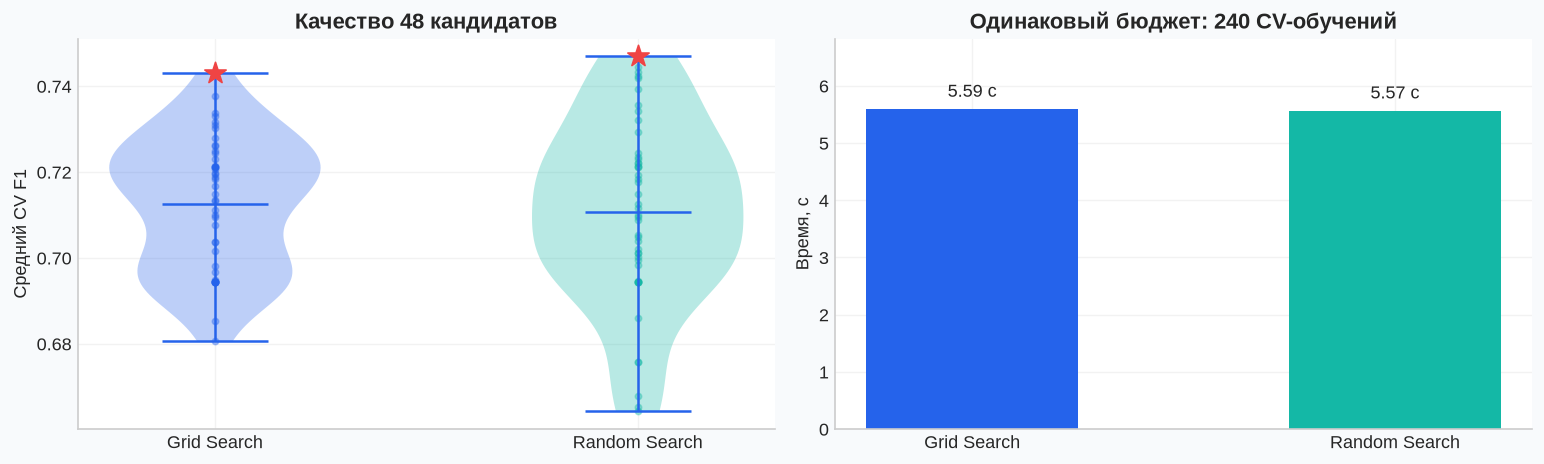

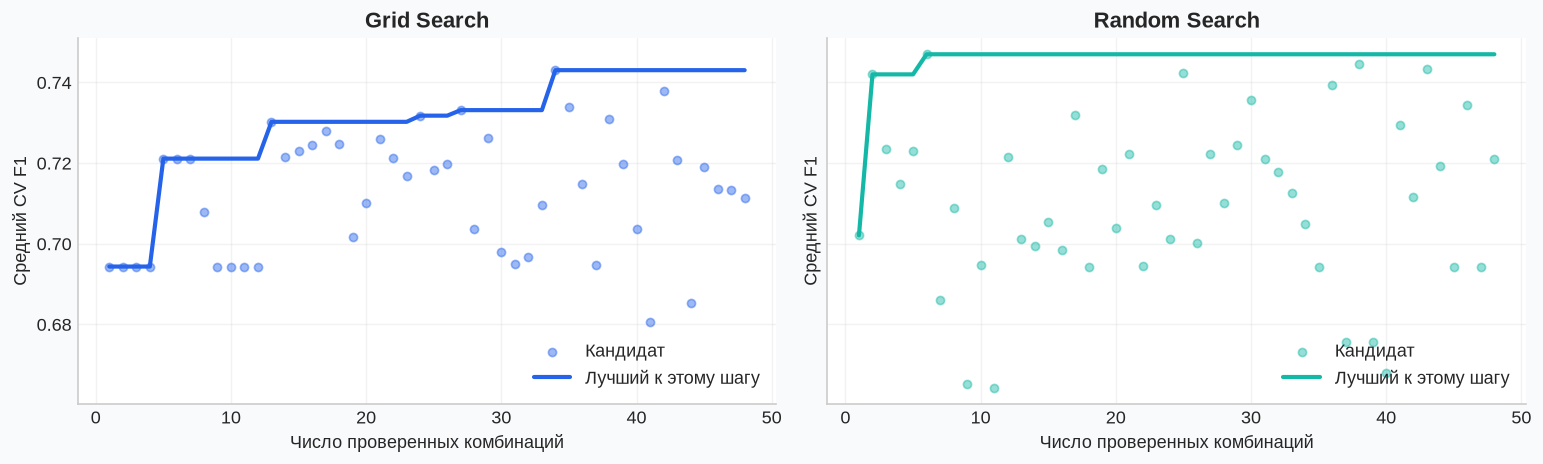

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = list(searches)
values = [s.cv_results_['mean_test_score'] for s in searches.values()]
parts = axes[0].violinplot(values, positions=[0, 1], showmeans=True, showextrema=True)
parts['bodies'][0].set_facecolor(COLORS[1])
parts['bodies'][1].set_facecolor(COLORS[2])
for i, scores in enumerate(values):
    axes[0].scatter(np.full(len(scores), i), scores, s=14, alpha=0.35, color=COLORS[i+1])
    axes[0].scatter(i, max(scores), marker='*', s=180, color='#ef4444', zorder=5)
axes[0].set(xticks=[0, 1], xticklabels=names, ylabel='Средний CV F1', title='Качество 48 кандидатов')
bars = axes[1].bar(names, [times[name] for name in names], color=COLORS[1:], width=0.5)
axes[1].bar_label(bars, fmt='%.2f с', padding=5)
axes[1].set(ylabel='Время, с', title='Одинаковый бюджет: 240 CV-обучений')
axes[1].set_ylim(0, max(times.values()) * 1.22)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'search_distribution_budget.png')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, search), color in zip(axes, searches.items(), COLORS[1:]):
    scores = np.asarray(search.cv_results_['mean_test_score'])
    steps = np.arange(1, len(scores)+1)
    ax.scatter(steps, scores, color=color, alpha=0.45, s=24, label='Кандидат')
    ax.plot(steps, np.maximum.accumulate(scores), color=color, lw=2.5, label='Лучший к этому шагу')
    ax.set(title=name, xlabel='Число проверенных комбинаций', ylabel='Средний CV F1')
    ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(ARTIFACTS / 'search_progress.png')
plt.show()

### Взаимодействие глубины и размера листа

Каждая ячейка тепловой карты показывает средний CV F1 одной конфигурации Grid Search. Для каждого значения `max_features` я строю отдельную панель с общей цветовой шкалой. Так видно, что полезность глубины зависит от размера листа и доступного числа признаков.

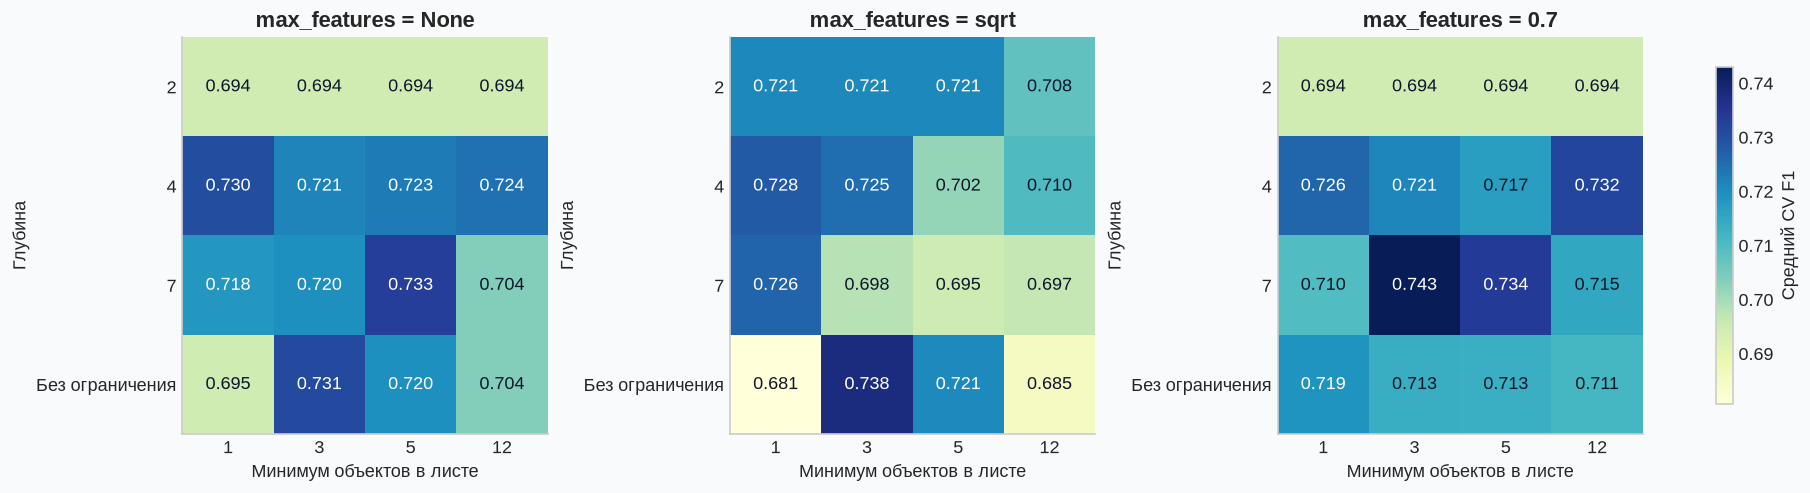

In [5]:
grid_results = pd.DataFrame(searches['Grid Search'].cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
low = grid_results.mean_test_score.min()
high = grid_results.mean_test_score.max()
for ax, feature_value in zip(axes, grid_space['model__max_features']):
    matrix = np.array([
        [next(row['mean_test_score'] for _, row in grid_results.iterrows()
              if row['params']['model__max_depth'] == depth
              and row['params']['model__min_samples_leaf'] == leaf
              and row['params']['model__max_features'] == feature_value)
         for leaf in grid_space['model__min_samples_leaf']]
        for depth in grid_space['model__max_depth']])
    im = ax.imshow(matrix, cmap='YlGnBu', vmin=low, vmax=high, aspect='auto')
    ax.set(xticks=range(4), xticklabels=grid_space['model__min_samples_leaf'],
           yticks=range(4), yticklabels=['2', '4', '7', 'Без ограничения'],
           xlabel='Минимум объектов в листе', ylabel='Глубина',
           title=f'max_features = {feature_value}')
    ax.grid(False)
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, f'{value:.3f}', ha='center', va='center',
                color='white' if value > low + 0.6*(high-low) else '#0f172a')
fig.colorbar(im, ax=axes, label='Средний CV F1', shrink=0.85)
plt.savefig(ARTIFACTS / 'grid_heatmaps.png')
plt.show()

## 3. Как параметры меняют сложность модели

Я строю validation curves вокруг выбранной по CV конфигурации: меняю один параметр, сохраняя остальные. Так можно проследить его влияние при фиксированном окружении, хотя взаимодействия параметров остаются за рамками одномерного графика.

Синяя линия показывает качество на обучении, оранжевая — на валидации. Полоса вокруг каждой линии соответствует одному стандартному отклонению по folds (`ddof=0`) и не является доверительным интервалом.

| Наблюдение | Возможная интерпретация |
|:---|:---|
| Невысокие train и validation F1 | Модели не хватает сложности |
| Высокий train F1 при снижении validation F1 | Модель запоминает особенности обучения |
| Высокий validation F1 с умеренным разрывом | Удачный компромисс сложности и обобщения |


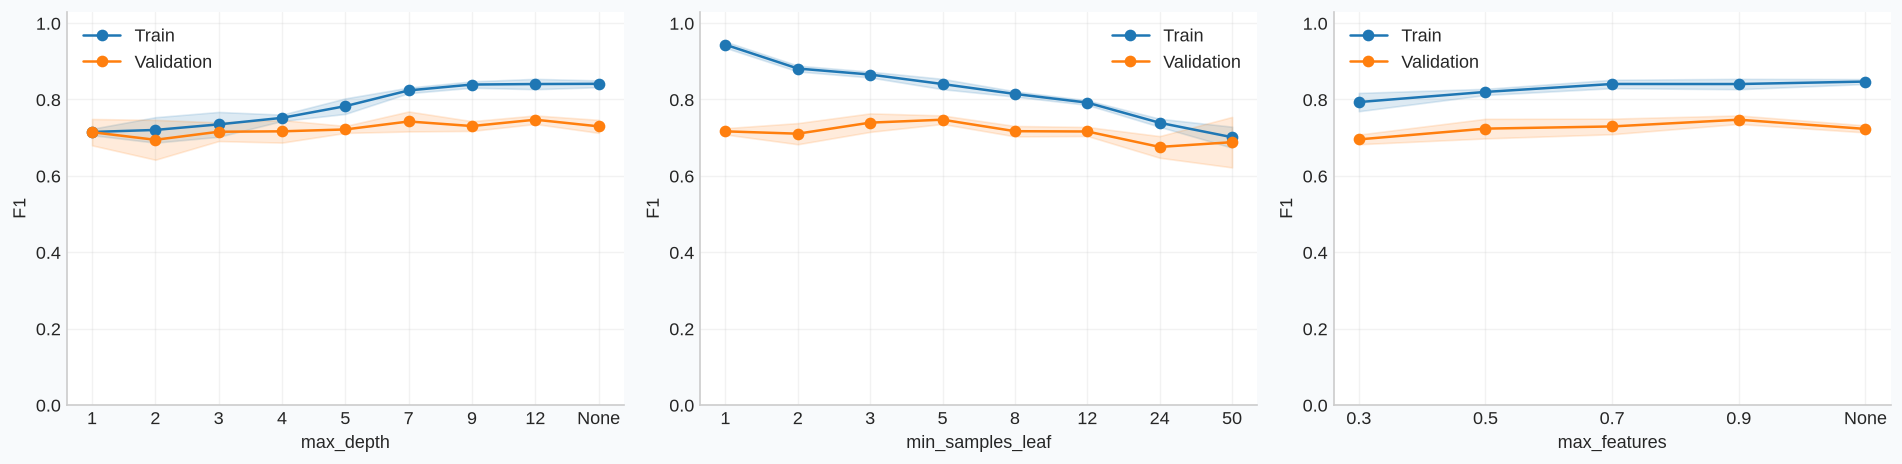

,parameter,value,train_F1,CV_F1,CV_std,gap
0,model__max_depth,1,0.7148,0.7143,0.0345,0.0005
1,model__max_depth,2,0.7201,0.6943,0.0522,0.0258
2,model__max_depth,3,0.7347,0.7154,0.0244,0.0193
3,model__max_depth,4,0.7518,0.7165,0.0296,0.0353
4,model__max_depth,5,0.7824,0.7214,0.0091,0.0610
5,model__max_depth,7,0.8237,0.7423,0.0262,0.0813
6,model__max_depth,9,0.8390,0.7303,0.0128,0.1087
7,model__max_depth,12,0.8403,0.7469,0.0112,0.0934
8,model__max_depth,None,0.8409,0.7295,0.0171,0.1114
9,model__min_samples_leaf,1,0.9433,0.7165,0.0083,0.2269


**model__max_depth**: максимум условной CV-кривой при 12 (F1=0.7469); максимальный разрыв train−validation при None (0.1114).

**model__min_samples_leaf**: максимум условной CV-кривой при 5 (F1=0.7469); максимальный разрыв train−validation при 1 (0.2269).

**model__max_features**: максимум условной CV-кривой при 0.9 (F1=0.7469); максимальный разрыв train−validation при None (0.1240).

In [6]:
curve_space = {'model__max_depth': [1, 2, 3, 4, 5, 7, 9, 12, None],
               'model__min_samples_leaf': [1, 2, 3, 5, 8, 12, 24, 50],
               'model__max_features': [0.3, 0.5, 0.7, 0.9, None]}
curve_model = clone(baseline).set_params(**selected_params)
curve_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (parameter, values) in zip(axes, curve_space.items()):
    train_scores, val_scores = validation_curve(
        curve_model, X_train, y_train, param_name=parameter, param_range=values,
        scoring='f1', cv=cv, n_jobs=1, error_score='raise')
    x = np.arange(len(values))
    for scores, label, color in [(train_scores, 'Train', 'tab:blue'),
                                  (val_scores, 'Validation', 'tab:orange')]:
        mean, std = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(x, mean, marker='o', label=label, color=color)
        ax.fill_between(x, mean - std, mean + std, alpha=0.15, color=color)
    ax.set(xticks=x, xticklabels=[str(v) for v in values],
           xlabel=parameter.removeprefix('model__'), ylabel='F1', ylim=(0, 1.03))
    ax.legend()
    for value, tr, va in zip(values, train_scores, val_scores):
        curve_rows.append({'parameter': parameter, 'value': str(value),
                           'train_F1': tr.mean(), 'CV_F1': va.mean(),
                           'CV_std': va.std(), 'gap': tr.mean() - va.mean()})
plt.tight_layout()
plt.savefig(ARTIFACTS / 'validation_curves.png')
plt.show()
curves = pd.DataFrame(curve_rows)
curves.to_csv(ARTIFACTS / 'validation_curves.csv', index=False)
display(curves.round(4))
for parameter in curve_space:
    part = curves[curves.parameter == parameter]
    peak = part.loc[part.CV_F1.idxmax()]
    gap = part.loc[part.gap.idxmax()]
    display(Markdown(f"**{parameter}**: максимум условной CV-кривой при {peak['value']} "
                     f"(F1={peak.CV_F1:.4f}); максимальный разрыв train−validation "
                     f"при {gap['value']} ({gap.gap:.4f})."))

## 4. Устойчивость на разных folds

Я сравниваю модели на одинаковых folds: рассматриваю среднее, стандартное отклонение, минимум и максимум F1. При близком среднем меньший разброс означает более ровное качество на этих разбиениях, но не гарантирует устойчивость на других данных.

Различия могут быть связаны с небольшим числом пассажиров и распределением возрастов, классов и семей между folds. Оптимизация среднего качества не обязательно уменьшает разброс. По пяти folds с пересекающимися обучающими частями я не делаю вывод о статистически значимом превосходстве одной модели.


,Baseline,Grid Search,Random Search
fold,,,
1,0.747664,0.780952,0.747664
2,0.693069,0.640777,0.733945
3,0.767677,0.795918,0.761062
4,0.716981,0.740000,0.757282
5,0.740000,0.757282,0.734694


,mean,std_ddof0,min,max
Baseline,0.733078,0.025759,0.693069,0.767677
Grid Search,0.742986,0.054595,0.640777,0.795918
Random Search,0.746929,0.011187,0.733945,0.761062


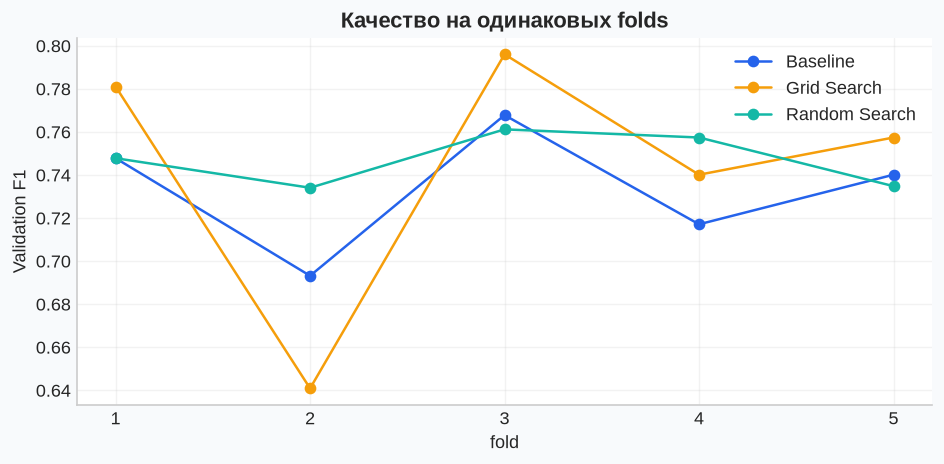

In [7]:
fold_scores = {'Baseline': base_cv['test_score']}
train_means = {'Baseline': base_cv['train_score'].mean()}
for name, search in searches.items():
    k = search.best_index_
    fold_scores[name] = np.array([search.cv_results_[f'split{i}_test_score'][k]
                                  for i in range(len(cv))])
    train_means[name] = search.cv_results_['mean_train_score'][k]
fold_table = pd.DataFrame(fold_scores, index=pd.Index(range(1, 6), name='fold'))
display(fold_table)
fold_table.to_csv(ARTIFACTS / 'fold_scores.csv')
stability = pd.DataFrame({name: {'mean': scores.mean(), 'std_ddof0': scores.std(),
                                'min': scores.min(), 'max': scores.max()}
                          for name, scores in fold_scores.items()}).T
display(stability)
fold_table.plot(marker='o', figsize=(8, 4), ylabel='Validation F1', xticks=range(1, 6),
                title='Качество на одинаковых folds')
plt.tight_layout()
plt.savefig(ARTIFACTS / 'fold_scores.png')
plt.show()

## 5. Проверка на отложенной выборке

После завершения поиска я фиксирую параметры и обучаю три конфигурации на всём train. Затем оцениваю каждую на одном и том же test. Результаты test использую для итогового сравнения, сохраняя стратегию, выбранную по CV.


In [8]:
models = {'Baseline': clone(baseline)}
models.update({name: clone(baseline).set_params(**search.best_params_)
               for name, search in searches.items()})

X_test, y_test = df.loc[test_idx, FEATURES], df.loc[test_idx, 'Survived']
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({'model': name, 'CV_F1': fold_scores[name].mean(),
                 'CV_std': fold_scores[name].std(), 'CV_train_F1': train_means[name],
                 'Test_F1': f1_score(y_test, model.predict(X_test), zero_division=0)})
results = pd.DataFrame(rows).set_index('model')
results['CV_delta'] = results.CV_F1 - results.loc['Baseline', 'CV_F1']
results['Test_delta'] = results.Test_F1 - results.loc['Baseline', 'Test_F1']
display(results.round(4))
results.to_csv(ARTIFACTS / 'final_scores.csv')
metadata = {'versions': versions, 'seed': SEED, 'data_sha256': hashlib.sha256(raw).hexdigest(),
            'baseline_parameters': baseline.named_steps['model'].get_params(),
            'grid_space': grid_space, 'random_space': random_space,
            'budget_per_search': BUDGET, 'selected_strategy': selected_name,
            'selected_parameters': selected_params, 'search_seconds': times}
(ARTIFACTS / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
assert len(results) == 3 and np.isfinite(results.select_dtypes('number')).all().all()
for name in searches:
    r = results.loc[name]
    display(Markdown(f"**{name}** относительно baseline: ΔCV F1={r.CV_delta:+.4f} "
                     f"({100*r.CV_delta:+.2f} п.п.), ΔTest F1={r.Test_delta:+.4f} "
                     f"({100*r.Test_delta:+.2f} п.п.)."))
r = results.loc[selected_name]
display(Markdown(f"Финальная стратегия **{selected_name}** выбрана по CV F1={r.CV_F1:.4f}; "
                 f"её Test F1={r.Test_F1:.4f}. Параметры: `{selected_params}`."))
grid_score, random_score = searches['Grid Search'].best_score_, searches['Random Search'].best_score_
display(Markdown(f"Random − Grid по CV: {random_score-grid_score:+.4f}; "
                 f"время Grid={times['Grid Search']:.2f} с, Random={times['Random Search']:.2f} с. "
                 "Обе стратегии проверили по 48 комбинаций. Время зависит от машины и сложности кандидатов."))

,CV_F1,CV_std,CV_train_F1,Test_F1,CV_delta,Test_delta
model,,,,,,
Baseline,0.7331,0.0258,0.8242,0.7087,0.0000,0.0000
Grid Search,0.7430,0.0546,0.8150,0.7344,0.0099,0.0257
Random Search,0.7469,0.0112,0.8403,0.6767,0.0139,-0.0320


**Grid Search** относительно baseline: ΔCV F1=+0.0099 (+0.99 п.п.), ΔTest F1=+0.0257 (+2.57 п.п.).

**Random Search** относительно baseline: ΔCV F1=+0.0139 (+1.39 п.п.), ΔTest F1=-0.0320 (-3.20 п.п.).

Финальная стратегия **Random Search** выбрана по CV F1=0.7469; её Test F1=0.6767. Параметры: `{'model__min_samples_leaf': 5, 'model__max_features': 0.9, 'model__max_depth': 12}`.

Random − Grid по CV: +0.0039; время Grid=5.59 с, Random=5.57 с. Обе стратегии проверили по 48 комбинаций. Время зависит от машины и сложности кандидатов.

### Качество и структура ошибок

На столбчатой диаграмме я сопоставляю качество обучения, кросс-валидации и test. Полосы погрешности относятся только к CV и показывают стандартное отклонение по folds. Матрицы ошибок позволяют увидеть, какие именно прогнозы изменились после настройки.

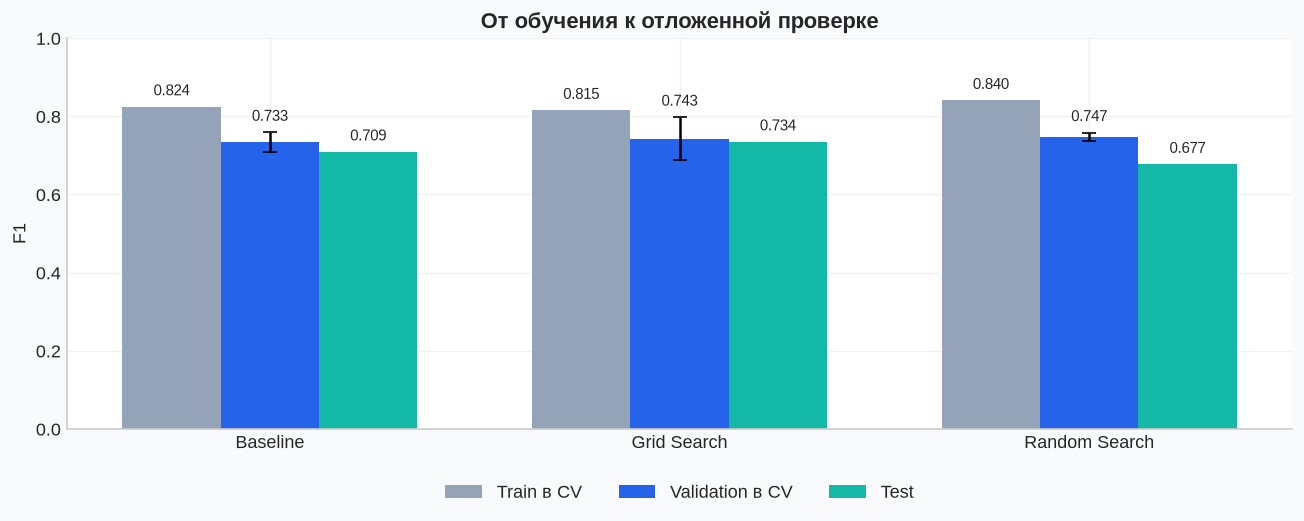

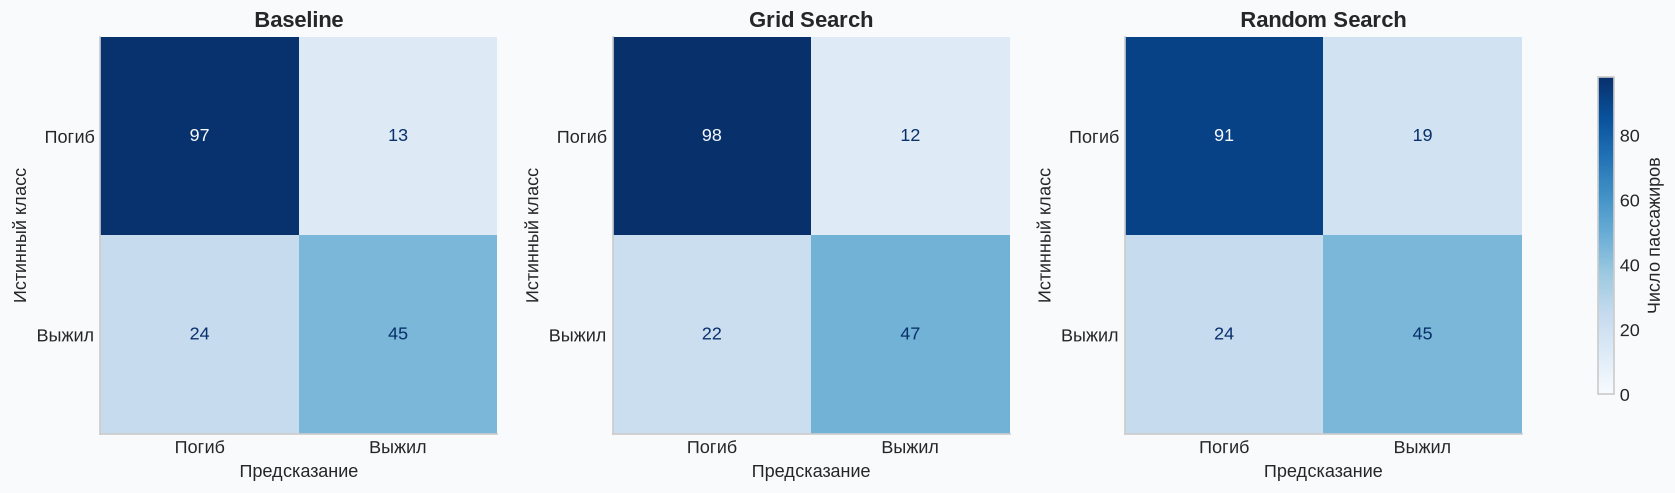

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(results))
width = 0.24
for offset, column, label, color in [(-width, 'CV_train_F1', 'Train в CV', '#94a3b8'),
                                      (0, 'CV_F1', 'Validation в CV', '#2563eb'),
                                      (width, 'Test_F1', 'Test', '#14b8a6')]:
    bars = ax.bar(x + offset, results[column], width, label=label, color=color,
                  yerr=results.CV_std if column == 'CV_F1' else None, capsize=4)
    ax.bar_label(bars, fmt='%.3f', padding=5, fontsize=9)
ax.set(xticks=x, xticklabels=results.index, ylabel='F1', ylim=(0, 1),
       title='От обучения к отложенной проверке')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'quality_comparison.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
matrices = {name: confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
            for name, model in models.items()}
maximum = max(matrix.max() for matrix in matrices.values())
for ax, (name, matrix) in zip(axes, matrices.items()):
    plot = ConfusionMatrixDisplay(matrix, display_labels=['Погиб', 'Выжил'])
    plot.plot(ax=ax, cmap='Blues', colorbar=False, im_kw={'vmin': 0, 'vmax': maximum})
    ax.set(title=name, xlabel='Предсказание', ylabel='Истинный класс')
    ax.grid(False)
fig.colorbar(plot.im_, ax=axes, shrink=0.8, label='Число пассажиров')
plt.savefig(ARTIFACTS / 'confusion_matrices.png')
plt.show()

## 6. Обсуждение

С увеличением глубины дерево получает возможность строить больше разбиений. Ограничение размера листа, напротив, мешает подгонять прогноз под отдельных пассажиров. F1 дискретен и немонотонен, поэтому рост сложности не гарантирует улучшения даже на обучении. Эффект `max_features` зависит от доступности полезных разбиений и взаимодействует с другими настройками.

Я ожидаю, что изменения CV и test могут различаться и по величине, и по знаку: в test всего 179 пассажиров, состав выборок различается, а лучший CV результат выбран из множества кандидатов. Ухудшение test не использую как повод для повторного подбора.

Для более строгой оценки всей процедуры поиска я мог бы применить вложенную CV или новый внешний test. Для проверки переноса на новые группы пассажиров потребовалось бы отдельное разбиение по билетам или семьям.


## 7. Выводы

- **Недообучение:** глубина 1 даёт train/validation F1 ≈ 0.714/0.714; при `min_samples_leaf=50` получаем 0.701/0.688. Простая модель не описывает часть закономерностей.
- **Разумная сложность:** при остальных параметрах победителя глубина 7–12 даёт CV F1 0.742–0.747. Лучшее значение на условной кривой размера листа — 5 (0.747). Разрыв train/validation остаётся около 0.093, то есть переобучение полностью не устранено.
- **Переобучение:** лист из одного объекта даёт train F1=0.943 и validation F1=0.716. Неограниченная глубина повышает train до 0.841, но снижает validation до 0.729 по сравнению с глубиной 12. Ограничение листьев сильнее сдерживает запоминание отдельных наблюдений.
- **Число доступных признаков:** доля 0.3 даёт CV F1=0.695, доля 0.9 — 0.747, все признаки — 0.723. Эффект немонотонен: один случайный seed и взаимодействия параметров не позволяют считать 0.9 универсально лучшим значением.
- **Поиски:** Grid дал CV F1=0.7430, Random — 0.7469 при равном числе обучений. Разница всего 0.0039. Разброс победителей на folds: 0.0546 и 0.0112 соответственно; Random оказался ровнее на этих пяти разбиениях. Это описательное сравнение после выбора кандидатов.
- **Итог:** baseline CV/test F1=0.7331/0.7087; Grid — 0.7430/0.7344; Random — 0.7469/0.6767. Выбранный заранее по CV Random улучшил CV на 1.39 п.п., но ухудшил test на 3.20 п.п. Grid повысил test на 2.57 п.п. Несмотря на это, я сохраняю финальный выбор: замена победителя по test нарушила бы протокол. Более ровные folds не гарантировали лучшего результата на отложенной выборке.

Таким образом, оптимизация повысила выбранную CV-метрику, но улучшение не перенеслось на test для финальной стратегии. Поэтому я сохраняю выбранную по CV модель и отмечаю ограничение обобщающей способности на этой выборке.
